# Parte de Candela - Outliers, Groupby, EDA y Visualizacion


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

In [18]:
URL = "https://raw.githubusercontent.com/SantinoCasado/tpi-analisis-de-datos-Grupo11-2026/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
df.shape

(7043, 21)

In [ ]:
# provisional para poder avanzar. Se debe borrar para main
df_clean = df.copy()
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)

In [20]:
df_clean["Churn_num"] = (df_clean["Churn"] == "Yes").astype(int)
COLORES = {"No": "#2a78d6", "Yes": "#eb6834"} #azul = se queda, naranja = se va

In [21]:
print(df_clean["TotalCharges"].isna().sum())
print((df_clean["TotalCharges"] == 0).sum())
print(df_clean["Churn_num"].mean().round(3))

0
11
0.265


# Paso 1: Outliers (Tarea JIRA: GIADD-7)

In [22]:
columnas = ["tenure", "MonthlyCharges", "TotalCharges"]
for col in columnas:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < limite_inferior) | (df_clean[col] > limite_superior)]

    print(col)
    print("Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2))
    print("Limites:", round(limite_inferior, 2), "a", round(limite_superior, 2))
    print("Minimo:", df_clean[col].min(), "| Maximo:", df_clean[col].max())
    print("Cantidad de Outliers:", len(outliers))
    print("-" * 40)

tenure
Q1: 9.0 | Q3: 55.0 | IQR: 46.0
Limites: -60.0 a 124.0
Minimo: 0 | Maximo: 72
Cantidad de Outliers: 0
----------------------------------------
MonthlyCharges
Q1: 35.5 | Q3: 89.85 | IQR: 54.35
Limites: -46.02 a 171.38
Minimo: 18.25 | Maximo: 118.75
Cantidad de Outliers: 0
----------------------------------------
TotalCharges
Q1: 398.55 | Q3: 3786.6 | IQR: 3388.05
Limites: -4683.52 a 8868.67
Minimo: 0.0 | Maximo: 8684.8
Cantidad de Outliers: 0
----------------------------------------


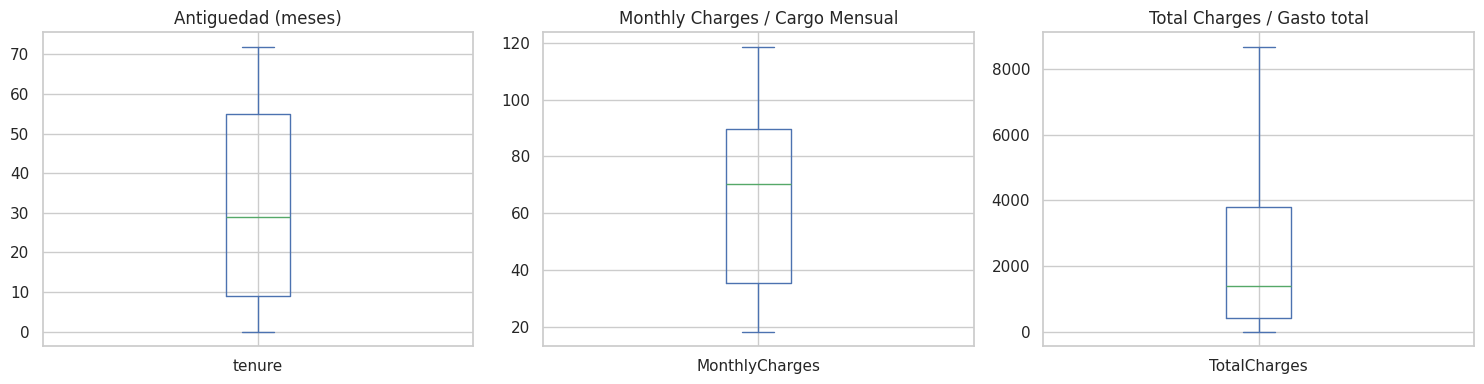

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_clean["tenure"].plot(kind="box", ax=axes[0])
axes[0].set_title("Antiguedad (meses)")

df_clean["MonthlyCharges"].plot(kind="box", ax=axes[1])
axes[1].set_title("Monthly Charges / Cargo Mensual")

df_clean["TotalCharges"].plot(kind="box", ax=axes[2])
axes[2].set_title("Total Charges / Gasto total")

plt.tight_layout()
plt.show()

**¿Qué muestra?** La distribucion de tenure, MonthlyCharges y TotalCharges y si hay valores fuera de los bigotes (metodo IQR)

**Dato Concreto** Ninguna de las tres variables tienen outliers. 
- En *tenure* los limtes son [-60: 124] y los datos van de 0 a 72 meses
- En *MonthlyCharges* los limites son [-46,02; 171,38] y los datos van de 18.25 a 118,75
- En *TotalCharges* los limites [-4.6383,52; 8.868,67] y los datos van de 0 a 8.684,80

**Interpretacion:** Los valores altos son los clientes reales (con mucha antiguedad o planes caros), no errores de carga

**Decision de negocio** No se elimina ningun registro; `df_clean` queda como DataFrame final para el resto del analisis

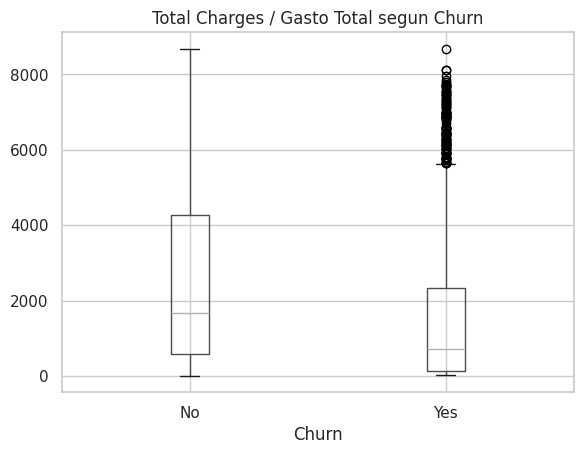

In [24]:
df_clean.boxplot(column="TotalCharges", by="Churn")
plt.title("Total Charges / Gasto Total segun Churn")
plt.suptitle("")
plt.show()

In [25]:
churn_si = df_clean[df_clean["Churn"] == "Yes"]

q1 = churn_si["TotalCharges"].quantile(0.25)
q3 = churn_si["TotalCharges"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

altos = churn_si[churn_si["TotalCharges"] > limite_superior]

print("Cantidad de valores altos:", len(altos))
print("Antiguedad promedio:", round(altos["tenure"].mean(), 1 ))
print("Cargo mensual promedio", round(altos["MonthlyCharges"].mean(), 2))
print("-" * 40)
print(altos["InternetService"].value_counts())

Cantidad de valores altos: 109
Antiguedad promedio: 63.9
Cargo mensual promedio 104.15
----------------------------------------
InternetService
Fiber optic    108
DSL              1
Name: count, dtype: int64


In [26]:
cociente = df_clean["TotalCharges"] / (df_clean["tenure"] * df_clean["MonthlyCharges"])
print("Mediana del cociente", round(cociente.median(), 2))

Mediana del cociente 1.0


**¿Qué muestra?** El gasto total separado entre clientes que se quedan (No) y que se van (Yes)

**Dato Concreto** Dentro de Churn = Yes hay 109 valores altos de TotalCharges; promedian 63,9 meses de antiguedad y 104,15 de cargo mensual, y 108 de ellos tienen `Fiber Optic`. Ademas TotalCharges ≈ tenure × MonthlyCharges (mediana del cociente = 1.00)

**Interpretacion** No son errores: son clientes antiguos con planes caros que igualmente se dieron de baja

**Decision de negocio** Se conservan, por que son los clientes mas valiosos perdidos y es importante estudiarlos y analizarlos (fibra optica con cargo alto). `df_clean` queda como dataFrame final